<a href="https://colab.research.google.com/github/YaseenRamzyy/ML-Assignment-2/blob/main/ML_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# hello
# MAZEN 5WL W OMAR BYTASSSSSSSSSSSS
# YASEEN BY5DO RASSSSS

# **Introduction to Machine Learning — Assignment 2**

## **0. Imports and reproducibility**

We use NumPy for the implementations, pandas for readable result tables, and matplotlib for plots. Scikit-learn is used only for loading the required datasets, splitting the data, and the explicit reference comparisons requested in the assignment.

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)

np.set_printoptions(precision=6, suppress=True)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("NumPy version:", np.__version__)
print("All randomness in this notebook uses random_state / default_rng seed 42.")

NumPy version: 2.4.6
All randomness in this notebook uses random_state / default_rng seed 42.


## **Part A — Data and toolkit**

### **Task 1. Load the four datasets and apply the required 60 / 20 / 20 split**

The assignment specifies:
1. Split 20% into the test set using `random_state=42`.
2. Split 25% of the remaining 80% into validation (which is 20% of the full dataset).
3. Use stratification for classification datasets, but not for Diabetes regression.

Dataset-specific preparation:
- Diabetes: `load_diabetes(scaled=False)`; keep the target in its original units.
- Breast Cancer: flip the labels so malignant = 1 and benign = 0.
- Digits: divide pixel values by 16; do not standardize them.
- Iris: use the original four features and three classes.

In [ ]:
# Load datasets exactly as described in the assignment

diabetes = load_diabetes(scaled=False)
breast = load_breast_cancer()
digits = load_digits()
iris = load_iris()

datasets = {}

# Diabetes: regression, so stratify=None

datasets["Diabetes"] = {
    "X": diabetes.data.astype(float),
    "y": diabetes.target.astype(float),
    "feature_names": list(diabetes.feature_names),
    "task": "regression"
}

# Breast Cancer: malignant must be the positive class (1)

datasets["Breast cancer"] = {
    "X": breast.data.astype(float),
    "y": (1 - breast.target).astype(int),
    "feature_names": list(breast.feature_names),
    "task": "classification"
}

# Digits: scale pixel intensities to [0, 1] by dividing by 16

datasets["Digits"] = {
    "X": digits.data.astype(float) / 16.0,
    "y": digits.target.astype(int),
    "feature_names": [f"pixel_{i}" for i in range(digits.data.shape[1])],
    "task": "classification"
}

datasets["Iris"] = {
    "X": iris.data.astype(float),
    "y": iris.target.astype(int),
    "feature_names": list(iris.feature_names),
    "task": "classification"
}

# Apply the exact two-step split protocol

splits = {}
for name, data in datasets.items():
    X, y = data["X"], data["y"]
    stratify_all = y if data["task"] == "classification" else None

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=stratify_all
    )

    stratify_train = y_train if data["task"] == "classification" else None
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=42,
        stratify=stratify_train
    )

    splits[name] = {
        "X_train": X_train, "X_val": X_val, "X_test": X_test,
        "y_train": y_train, "y_val": y_val, "y_test": y_test,
        "feature_names": data["feature_names"],
        "task": data["task"]
    }

# Required split sizes

expected_sizes = {
    "Diabetes": (264, 89, 89, 442),
    "Breast cancer": (341, 114, 114, 569),
    "Digits": (1077, 360, 360, 1797),
    "Iris": (90, 30, 30, 150)
}

rows = []

for name, sp in splits.items():

    sizes = tuple(len(sp[k]) for k in ["y_train", "y_val", "y_test"])
    total = sum(sizes)
    rows.append([name, *sizes, total, expected_sizes[name]])
    assert sizes + (total,) == expected_sizes[name], f"Unexpected split sizes for {name}"

split_table = pd.DataFrame(
    [[r[0], r[1], r[2], r[3], r[4]] for r in rows],
    columns=["Dataset", "Train", "Validation", "Test", "Total"]
)

display(split_table)
print("All split sizes match the assignment.")

,Dataset,Train,Validation,Test,Total
0,Diabetes,264,89,89,442
1,Breast cancer,341,114,114,569
2,Digits,1077,360,360,1797
3,Iris,90,30,30,150


All split sizes match the assignment.


### Task 1 — Classification class counts

The next table prints the number of examples from every class in each classification split. Stratification keeps the class proportions approximately the same across training, validation, and test sets.

In [ ]:
for name in ["Breast cancer", "Digits", "Iris"]:
    sp = splits[name]
    print(f"\n{name}")
    classes = np.unique(datasets[name]["y"])

    count_table = pd.DataFrame({
        "Train": [np.sum(sp["y_train"] == c) for c in classes],
        "Validation": [np.sum(sp["y_val"] == c) for c in classes],
        "Test": [np.sum(sp["y_test"] == c) for c in classes]
    }, index=classes)

    count_table.index.name = "Class"
    display(count_table)

**Task 2 — Why training-only statistics matter (two sentences).**

The mean and standard deviation must be calculated from training rows only so that validation and test data remain unseen when the model is being prepared and evaluated. If we calculate these statistics using all rows, information about the test distribution leaks into training, making the final test result less independent and potentially misleading.

### **Task 3. Implement regression and classification metrics**

We implement:
- MSE, RMSE, and R² for regression.
- Accuracy and a confusion matrix for classification.
- Per-class precision, recall, and F1, plus macro averages.

For the confusion matrix, rows are the true classes and columns are predicted classes. **Precision is defined as 0 when a class is never predicted**, as required.

In [ ]:
def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot


def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def confusion_matrix(y_true, y_pred, K):

    # Rows = true class, columns = predicted class
    cm = np.zeros((K, K), dtype=int)
    for true_label, pred_label in zip(y_true, y_pred):
        cm[int(true_label), int(pred_label)] += 1
    return cm


def classification_metrics_from_cm(cm):
    cm = np.asarray(cm)
    true_positive = np.diag(cm)
    predicted_count = np.sum(cm, axis=0)
    actual_count = np.sum(cm, axis=1)

    # Required convention: precision = 0 if a class is never predicted
    precision = np.divide(
        true_positive, predicted_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=predicted_count != 0
    )
    recall = np.divide(
        true_positive, actual_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=actual_count != 0
    )
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }


print("Metric functions are ready.")

#### **Task 3 verification against scikit-learn**

We generate 500 random true and predicted labels with four classes. Every metric is compared against the corresponding scikit-learn metric, and the absolute differences must be no larger than $ 10^{-12} $.

In [ ]:
from sklearn.metrics import (
    mean_squared_error as sk_mse,
    mean_absolute_error,
    r2_score as sk_r2,
    accuracy_score as sk_accuracy,
    confusion_matrix as sk_cm
)

check_rng = np.random.default_rng(42)
N_check, K_check = 500, 4
y_true_check = check_rng.integers(0, K_check, size=N_check)
y_pred_check = check_rng.integers(0, K_check, size=N_check)

# Regression metric checks on random continuous values
y_reg = check_rng.normal(size=500)
y_reg_pred = y_reg + check_rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_reg_pred) - sk_mse(y_reg, y_reg_pred)) < 1e-12
assert abs(rmse(y_reg, y_reg_pred) - np.sqrt(sk_mse(y_reg, y_reg_pred))) < 1e-12
assert abs(r2(y_reg, y_reg_pred) - sk_r2(y_reg, y_reg_pred)) < 1e-12

# Classification metric checks
cm_ours = confusion_matrix(y_true_check, y_pred_check, K_check)
cm_sklearn = sk_cm(y_true_check, y_pred_check, labels=np.arange(K_check))
assert np.array_equal(cm_ours, cm_sklearn)
assert abs(accuracy(y_true_check, y_pred_check) -
           sk_accuracy(y_true_check, y_pred_check)) < 1e-12

ours = classification_metrics_from_cm(cm_ours)
sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(
    y_true_check, y_pred_check, labels=np.arange(K_check),
    zero_division=0
)

assert np.max(np.abs(ours["precision"] - sk_precision)) < 1e-12
assert np.max(np.abs(ours["recall"] - sk_recall)) < 1e-12
assert np.max(np.abs(ours["f1"] - sk_f1)) < 1e-12
assert abs(ours["macro_precision"] - np.mean(sk_precision)) < 1e-12
assert abs(ours["macro_recall"] - np.mean(sk_recall)) < 1e-12
assert abs(ours["macro_f1"] - np.mean(sk_f1)) < 1e-12

print("All Task 3 checks passed: differences are below 1e-12.")
print("Our confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(cm_ours))

### Task 4. Numerical gradient checker

The gradient checker uses central differences:
$$
\
g_i^{num}=\frac{f(w+\epsilon e_i)-f(w-\epsilon e_i)}{2\epsilon}.
\
$$

It returns the relative error between the analytic and numerical gradients. The assignment asks for $ \epsilon=10^{-5} $ generally and $ 10^{-6} $ for hinge losses. For this task we implement the general checker; later tasks can pass a different epsilon when needed.

In [ ]:
def grad_check(f, grad, w, epsilon=1e-5):
    w = np.asarray(w, dtype=float)
    numerical = np.zeros_like(w)

    for i in range(w.size):
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += epsilon
        w_minus.flat[i] -= epsilon
        numerical.flat[i] = (f(w_plus) - f(w_minus)) / (2 * epsilon)

    analytic = np.asarray(grad(w), dtype=float)
    numerator = np.linalg.norm(analytic - numerical)
    denominator = max(np.linalg.norm(analytic), np.linalg.norm(numerical), 1e-12)
    return numerator / denominator


# Small demonstration using f(w) = sum(w_i^2), gradient = 2w
w_demo = np.random.default_rng(42).normal(0, 0.1, size=8)
demo_error = grad_check(
    lambda w: np.sum(w ** 2),
    lambda w: 2 * w,
    w_demo
)
print("Demonstration relative gradient error:", demo_error)
assert demo_error < 1e-6

---

# Part B — Linear Regression

**Dataset:** Diabetes. Features are standardized using training statistics only; the target remains in its original units.

The model is:
$$
\
\hat y=\widetilde Xw,\qquad
J(w)=\frac{1}{2N}\|\widetilde Xw-y\|^2,
\
$$

where $\widetilde X=[1\mid X]\$ and The first weight is the intercept and is not regularized in the ridge task.

## Task 5. Closed-form solution (normal equation)

Starting with
$$
J(w)=\frac{1}{2N}(\widetilde Xw-y)^T(\widetilde Xw-y),
$$
differentiate with respect to \(w\):
$$
\nabla J(w)=\frac{1}{N}\widetilde X^T(\widetilde Xw-y).
$$
At the minimum, set the gradient to zero:
$$
\widetilde X^T\widetilde Xw=\widetilde X^Ty.
$$
Therefore, solve this linear system for \(w\). We use `np.linalg.solve`, not an explicit matrix inverse.

In [ ]:
# Prepare standardized Diabetes data and add the intercept column
diab = standardized_splits["Diabetes"]
Xtr = add_bias(diab["X_train"])
Xva = add_bias(diab["X_val"])
Xte = add_bias(diab["X_test"])
ytr, yva, yte = diab["y_train"], diab["y_val"], diab["y_test"]
diabetes_feature_names = ["bias"] + splits["Diabetes"]["feature_names"]


def normal_equation(X, y):
    # Solve (X.T @ X) w = X.T @ y without explicitly computing an inverse
    return np.linalg.solve(X.T @ X, X.T @ y)


w_star = normal_equation(Xtr, ytr)
pred_train = Xtr @ w_star
pred_val = Xva @ w_star
pred_test = Xte @ w_star

task5_results = pd.DataFrame({
    "Feature": diabetes_feature_names,
    "Weight": w_star
})
display(task5_results)

task5_metrics = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "RMSE": [
        rmse(ytr, pred_train),
        rmse(yva, pred_val),
        rmse(yte, pred_test)
    ]
})

display(task5_metrics)
print("Test R²:", r2(yte, pred_test))
print("Condition number of X.T @ X:", np.linalg.cond(Xtr.T @ Xtr))

### Task 5 verification against scikit-learn LinearRegression

We fit `LinearRegression` on the exact same standardized training features. The coefficient vector and intercept should match our normal-equation weights within $ 10^{-6} $.

In [ ]:
linear_reference = LinearRegression()
linear_reference.fit(Xtr[:, 1:], ytr)
w_reference = np.concatenate(([linear_reference.intercept_], linear_reference.coef_))
weight_difference = np.max(np.abs(w_star - w_reference))

print("Maximum absolute weight difference:", weight_difference)
assert weight_difference < 1e-6
print("Verification passed.")

**Task 5 — Interpreting selected weights (s1, s2, and bmi).**

The coefficients below show the direction and size of each feature's contribution when the other features are held fixed. A positive coefficient increases the prediction, while a negative coefficient decreases it. Individual coefficients can be difficult to interpret when features are correlated because correlated features share information, so a change in one coefficient may be compensated for by another.

In [ ]:
for feature in ["s1", "s2", "bmi"]:
    idx = diabetes_feature_names.index(feature)
    print(f"{feature}: {w_star[idx]:.6f}")

Part D


ana 3mlt task 18 y Mazen

Training shape: (1077, 65)
Validation shape: (360, 65)
Test shape: (360, 65)
Number of classes: 10

Task 18(a): Learning Rate Comparison


,Learning Rate,Final Train Loss,Final Validation Loss,Final Train Accuracy,Final Validation Accuracy
0,0.01,0.8086,0.8374,0.9248,0.9111
1,0.10,0.2038,0.2390,0.9601,0.9500
2,0.50,0.0868,0.1383,0.9889,0.9611
3,1.00,0.0566,0.1193,0.9963,0.9611


Selected learning rate eta* = 1.0


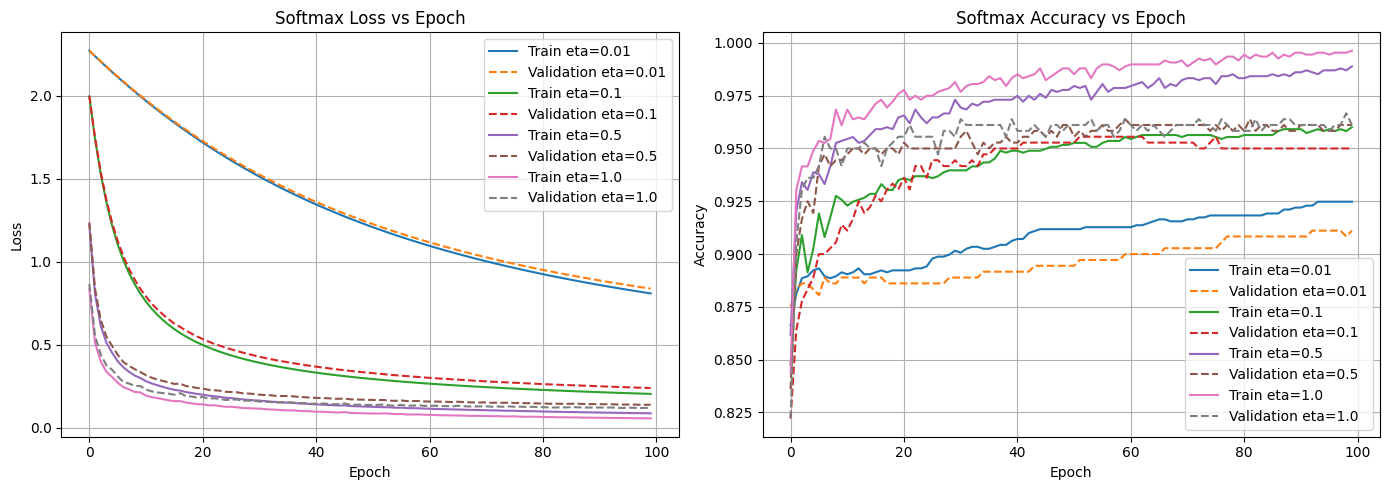


Task 18(b): Regularization Comparison


,Lambda,Final Train Loss,Final Validation Loss,Train Accuracy,Validation Accuracy
0,0.0000,0.0566,0.1193,0.9963,0.9611
1,0.0001,0.0916,0.1508,0.9963,0.9639
2,0.0010,0.2580,0.3042,0.9805,0.9667
3,0.0100,0.7463,0.7856,0.9387,0.9278
4,0.1000,1.7751,1.8035,0.6416,0.6333


Selected lambda* = 0.001

Final Softmax Model
-------------------
Selected eta: 1.0
Selected lambda: 0.001
Test Loss: 0.3053
Test Accuracy: 0.9528
Test Accuracy (%): 95.28


In [ ]:

# Task 18 — Softmax training and model selection

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. Load Digits dataset (pixels / 16, no standardization)
# --------------------------------------------------

data = splits["Digits"]

X_train = data["X_train"]
X_val   = data["X_val"]
X_test  = data["X_test"]

y_train = data["y_train"].astype(int)
y_val   = data["y_val"].astype(int)
y_test  = data["y_test"].astype(int)

# Add bias column
X_train_tilde = np.column_stack((np.ones(len(X_train)), X_train))
X_val_tilde   = np.column_stack((np.ones(len(X_val)), X_val))
X_test_tilde  = np.column_stack((np.ones(len(X_test)), X_test))

K = len(np.unique(y_train))
D = X_train_tilde.shape[1]

print("Training shape:", X_train_tilde.shape)
print("Validation shape:", X_val_tilde.shape)
print("Test shape:", X_test_tilde.shape)
print("Number of classes:", K)


# --------------------------------------------------
# 2. Stable Softmax and Cross-Entropy Loss
# --------------------------------------------------

def softmax_loss_gradient(X, y, W, lam):
    """
    Softmax cross-entropy loss + L2 regularization.
    The first row of W is the bias and is NOT regularized.
    """

    N = X.shape[0]

    scores = X @ W

    # Stable log-sum-exp
    max_scores = np.max(scores, axis=1, keepdims=True)
    shifted_scores = scores - max_scores

    exp_scores = np.exp(shifted_scores)
    probabilities = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    log_sum_exp = np.log(np.sum(exp_scores, axis=1)) + max_scores.ravel()

    loss = np.mean(log_sum_exp - scores[np.arange(N), y])

    # Regularize weights only, not bias
    loss += (lam / 2) * np.sum(W[1:, :] ** 2)

    # Gradient
    dscores = probabilities.copy()
    dscores[np.arange(N), y] -= 1

    grad = (X.T @ dscores) / N
    grad[1:, :] += lam * W[1:, :]

    return loss, grad


# --------------------------------------------------
# 3. Prediction and Evaluation
# --------------------------------------------------

def predict_softmax(X, W):
    scores = X @ W
    return np.argmax(scores, axis=1)


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def evaluate_softmax(X, y, W, lam):
    loss, _ = softmax_loss_gradient(X, y, W, lam)
    acc = accuracy(y, predict_softmax(X, W))
    return loss, acc


# --------------------------------------------------
# 4. Mini-batch Gradient Descent
# --------------------------------------------------

def train_softmax(X_train, y_train, X_val, y_val,
                  eta, lam, epochs=100, batch_size=64):

    rng = np.random.default_rng(42)

    W = np.zeros((X_train.shape[1], K))

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    N = len(X_train)

    for epoch in range(epochs):

        # Shuffle training samples
        indices = rng.permutation(N)

        # Mini-batch updates
        for start in range(0, N, batch_size):

            batch_indices = indices[start:start + batch_size]

            X_batch = X_train[batch_indices]
            y_batch = y_train[batch_indices]

            _, grad = softmax_loss_gradient(
                X_batch, y_batch, W, lam
            )

            W -= eta * grad

        # Evaluate after each epoch
        train_loss, train_acc = evaluate_softmax(
            X_train, y_train, W, lam
        )

        val_loss, val_acc = evaluate_softmax(
            X_val, y_val, W, lam
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

    return W, history


# --------------------------------------------------
# 5. Task 18(a): Learning Rate Selection
# lambda = 0
# --------------------------------------------------

learning_rates = [0.01, 0.1, 0.5, 1.0]

eta_results = {}
eta_rows = []

for eta in learning_rates:

    W, history = train_softmax(
        X_train_tilde, y_train,
        X_val_tilde, y_val,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    eta_results[eta] = (W, history)

    eta_rows.append({
        "Learning Rate": eta,
        "Final Train Loss": history["train_loss"][-1],
        "Final Validation Loss": history["val_loss"][-1],
        "Final Train Accuracy": history["train_acc"][-1],
        "Final Validation Accuracy": history["val_acc"][-1]
    })


eta_table = pd.DataFrame(eta_rows)

print("\nTask 18(a): Learning Rate Comparison")
display(eta_table.round(4))

# Choose eta with lowest final validation loss
eta_star = min(
    learning_rates,
    key=lambda eta: eta_results[eta][1]["val_loss"][-1]
)

print("Selected learning rate eta* =", eta_star)


# --------------------------------------------------
# 6. Plot Loss and Accuracy for Different Learning Rates
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for eta in learning_rates:

    history = eta_results[eta][1]

    axes[0].plot(
        history["train_loss"],
        label=f"Train eta={eta}"
    )

    axes[0].plot(
        history["val_loss"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

    axes[1].plot(
        history["train_acc"],
        label=f"Train eta={eta}"
    )

    axes[1].plot(
        history["val_acc"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

axes[0].set_title("Softmax Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Softmax Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Task 18(b): Regularization Selection
# Use selected eta*
# --------------------------------------------------

lambda_values = [0, 1e-4, 1e-3, 1e-2, 1e-1]

lambda_results = {}
lambda_rows = []

for lam in lambda_values:

    W, history = train_softmax(
        X_train_tilde, y_train,
        X_val_tilde, y_val,
        eta=eta_star,
        lam=lam,
        epochs=100,
        batch_size=64
    )

    lambda_results[lam] = (W, history)

    lambda_rows.append({
        "Lambda": lam,
        "Final Train Loss": history["train_loss"][-1],
        "Final Validation Loss": history["val_loss"][-1],
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": history["val_acc"][-1]
    })


lambda_table = pd.DataFrame(lambda_rows)

print("\nTask 18(b): Regularization Comparison")
display(lambda_table.round(4))


# Choose highest validation accuracy.
# In case of a tie, choose the larger lambda.
lambda_star = max(
    lambda_values,
    key=lambda lam: (
        lambda_results[lam][1]["val_acc"][-1],
        lam
    )
)

W_softmax = lambda_results[lambda_star][0]

print("Selected lambda* =", lambda_star)


# --------------------------------------------------
# 8. Final Test Evaluation (only once)
# --------------------------------------------------

test_loss, test_acc = evaluate_softmax(
    X_test_tilde,
    y_test,
    W_softmax,
    lambda_star
)

print("\nFinal Softmax Model")
print("-------------------")
print("Selected eta:", eta_star)
print("Selected lambda:", lambda_star)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_acc, 4))
print("Test Accuracy (%):", round(test_acc * 100, 2))


# Save results for Task 25 comparison
softmax_results = {
    "eta_star": eta_star,
    "lambda_star": lambda_star,
    "W": W_softmax,
    "val_accuracy": lambda_results[lambda_star][1]["val_acc"][-1],
    "test_accuracy": test_acc
}


## Part E — Support Vector Machines (SVMs)

In this part, we will study Support Vector Machines and understand how they work for classification problems.

We will:
- Implement a Linear SVM from scratch using NumPy and understand the hinge loss and its subgradient.
- Compare our implementation with Scikit-learn's SVC and LinearSVC.
- Study how the regularization parameter (C) affects the margin, training accuracy, and support vectors.
- Explore different kernels, including Linear, Polynomial, and RBF.
- Investigate how the gamma parameter affects the decision boundary and model performance.
- Use Grid Search with cross-validation to find the best C and gamma values for the Digits dataset.

Gradient Check
Relative Error: 1.5909319306685128e-10
Passed: True

Schedule: constant_0.1
Final Objective: 0.06054418829142294
Final Validation Accuracy: 0.9736842105263158

Schedule: constant_1.0
Final Objective: 0.060961211232473875
Final Validation Accuracy: 0.9736842105263158

Schedule: decaying
Final Objective: 0.06079845566114743
Final Validation Accuracy: 0.9736842105263158


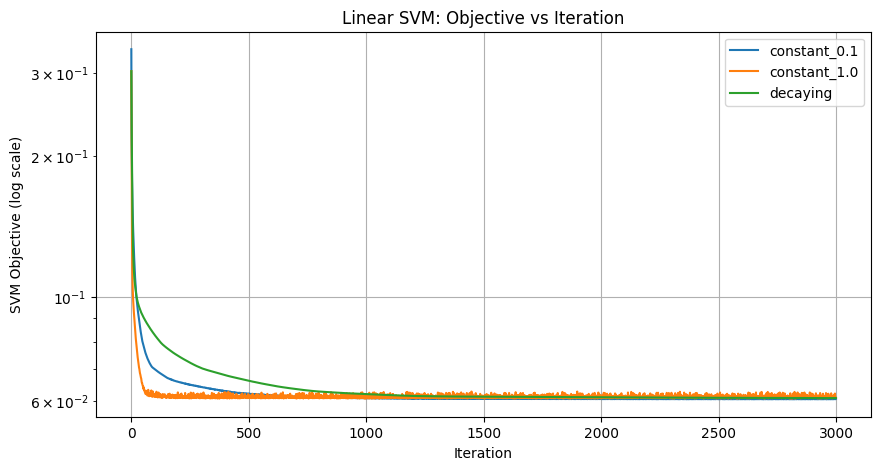

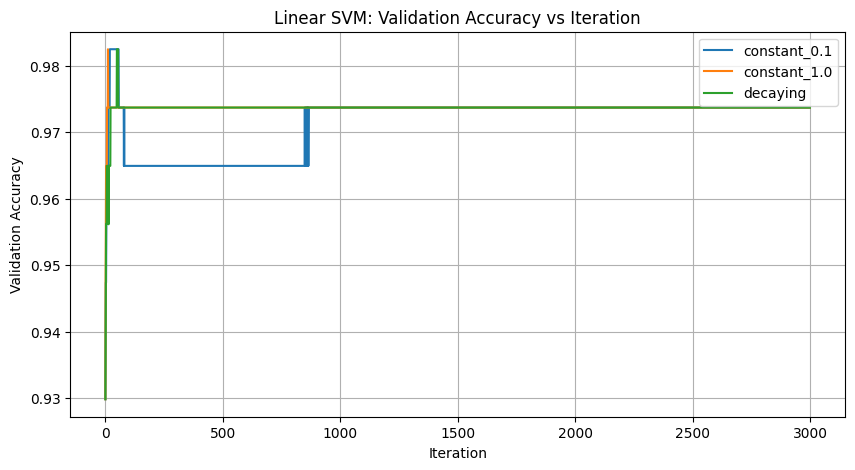


Explanation:

1. A constant learning rate may keep oscillating around the minimum
   because the hinge-loss subgradient does not necessarily become zero.

2. A decreasing learning rate reduces the update size over time,
   helping the algorithm approach a more stable solution.

3. A smaller constant learning rate can produce less oscillation
   and a better final result after a fixed number of iterations.

4. A larger learning rate may make faster progress initially,
   but its updates can overshoot the minimum.



In [ ]:

# Linear SVM from scratch

import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare Breast Cancer dataset
bc = splits["Breast cancer"]

X_train_raw = bc["X_train"]
X_val_raw = bc["X_val"]

# Convert labels: malignant = +1, benign = -1
y_train = 2 * bc["y_train"] - 1
y_val = 2 * bc["y_val"] - 1

# Standardization (fit on training data only)
class Standardizer:
    def fit(self, X):
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        self.std[self.std == 0] = 1
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

svm_scaler = Standardizer()
svm_scaler.fit(X_train_raw)

X_train = svm_scaler.transform(X_train_raw)
X_val = svm_scaler.transform(X_val_raw)

# 2. SVM Objective
lambda_reg = 0.01

def svm_objective(X, y, w, b, lam=lambda_reg):
    scores = X @ w + b
    hinge_loss = np.maximum(0, 1 - y * scores)
    regularization = (lam / 2) * np.sum(w ** 2)

    return regularization + np.mean(hinge_loss)


# 3. SVM Subgradient
def svm_gradient(X, y, w, b, lam=lambda_reg):
    N = X.shape[0]

    scores = X @ w + b
    margins = 1 - y * scores
    active = margins > 0

    dw = lam * w - (X[active].T @ y[active]) / N
    db = -np.sum(y[active]) / N

    return dw, db


# 4. Gradient Check
def gradient_check(X, y, lam=0.01, epsilon=1e-6):
    rng_check = np.random.default_rng(42)

    theta = rng_check.normal(0, 0.1, X.shape[1] + 1)
    w = theta[:-1]
    b = theta[-1]

    dw, db = svm_gradient(X, y, w, b, lam)
    analytical = np.concatenate([dw, [db]])

    numerical = np.zeros_like(theta)

    for j in range(len(theta)):
        theta_plus = theta.copy()
        theta_minus = theta.copy()

        theta_plus[j] += epsilon
        theta_minus[j] -= epsilon

        loss_plus = svm_objective(
            X, y, theta_plus[:-1], theta_plus[-1], lam
        )

        loss_minus = svm_objective(
            X, y, theta_minus[:-1], theta_minus[-1], lam
        )

        numerical[j] = (loss_plus - loss_minus) / (2 * epsilon)

    numerator = np.linalg.norm(analytical - numerical)
    denominator = max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

    return numerator / denominator


error = gradient_check(X_train, y_train)

print("Gradient Check")
print("Relative Error:", error)
print("Passed:", error < 1e-5)


# 5. Full-Batch Subgradient Descent
def train_svm(X, y, X_val, y_val, schedule, epochs=3000, lam=0.01):

    w = np.zeros(X.shape[1])
    b = 0.0

    losses = []
    val_accuracies = []

    for t in range(1, epochs + 1):

        if schedule == "constant_0.1":
            eta = 0.1

        elif schedule == "constant_1.0":
            eta = 1.0

        elif schedule == "decaying":
            eta = 1.0 / np.sqrt(t)

        dw, db = svm_gradient(X, y, w, b, lam)

        w -= eta * dw
        b -= eta * db

        # Objective
        losses.append(svm_objective(X, y, w, b, lam))

        # Validation accuracy
        predictions = np.where(X_val @ w + b >= 0, 1, -1)
        accuracy = np.mean(predictions == y_val)

        val_accuracies.append(accuracy)

    return w, b, losses, val_accuracies


# 6. Train using three learning-rate schedules
schedules = ["constant_0.1", "constant_1.0", "decaying"]

results = {}

for schedule in schedules:

    w, b, losses, val_acc = train_svm(
        X_train, y_train,
        X_val, y_val,
        schedule,
        epochs=3000,
        lam=lambda_reg
    )

    results[schedule] = {
        "w": w,
        "b": b,
        "losses": losses,
        "val_acc": val_acc
    }

    print("\nSchedule:", schedule)
    print("Final Objective:", losses[-1])
    print("Final Validation Accuracy:", val_acc[-1])


# 7. Plot Objective vs Iteration
plt.figure(figsize=(10, 5))

for schedule in schedules:
    plt.plot(results[schedule]["losses"], label=schedule)

plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("SVM Objective (log scale)")
plt.title("Linear SVM: Objective vs Iteration")
plt.legend()
plt.grid(True)
plt.show()


# 8. Plot Validation Accuracy vs Iteration
plt.figure(figsize=(10, 5))

for schedule in schedules:
    plt.plot(results[schedule]["val_acc"], label=schedule)

plt.xlabel("Iteration")
plt.ylabel("Validation Accuracy")
plt.title("Linear SVM: Validation Accuracy vs Iteration")
plt.legend()
plt.grid(True)
plt.show()


# 9. Theoretical explanation
print("""
Explanation:

1. A constant learning rate may keep oscillating around the minimum
   because the hinge-loss subgradient does not necessarily become zero.

2. A decreasing learning rate reduces the update size over time,
   helping the algorithm approach a more stable solution.

3. A smaller constant learning rate can produce less oscillation
   and a better final result after a fixed number of iterations.

4. A larger learning rate may make faster progress initially,
   but its updates can overshoot the minimum.
""")


In [ ]:
# Task 24 Comparison with Scikit-learn

import numpy as np
import pandas as pd
from sklearn.svm import SVC, LinearSVC
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 1. Prepare Breast Cancer data
bc = splits["Breast cancer"]

X_train_raw = bc["X_train"]
X_val_raw = bc["X_val"]
X_test_raw = bc["X_test"]

y_train = 2 * bc["y_train"] - 1
y_val = 2 * bc["y_val"] - 1
y_test = 2 * bc["y_test"] - 1

# Standardize using training data only
class Standardizer:
    def fit(self, X):
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        self.std[self.std == 0] = 1
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

scaler = Standardizer()
scaler.fit(X_train_raw)

X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

N_train = len(X_train)
lambda_reg = 0.01


# 2. SVM objective and gradient
def svm_objective(X, y, w, b, lam):
    scores = X @ w + b
    hinge = np.maximum(0, 1 - y * scores)

    regularization = (lam / 2) * np.sum(w ** 2)

    return regularization + np.mean(hinge)


def svm_gradient(X, y, w, b, lam):
    N = len(X)

    scores = X @ w + b
    margins = 1 - y * scores
    active = margins > 0

    dw = lam * w - (X[active].T @ y[active]) / N
    db = -np.sum(y[active]) / N

    return dw, db


# 3. Train from scratch for 20,000 iterations
def train_svm_scratch(X, y, lam, epochs=20000):
    w = np.zeros(X.shape[1])
    b = 0.0

    for t in range(1, epochs + 1):
        eta = 1.0 / np.sqrt(t)

        dw, db = svm_gradient(X, y, w, b, lam)

        w -= eta * dw
        b -= eta * db

    return w, b


# 4. Train our SVM with lambda = 0.01
w_ours, b_ours = train_svm_scratch(
    X_train, y_train, lambda_reg, epochs=20000
)

# 5. Train sklearn SVC with matching C
C_value = 1 / (lambda_reg * N_train)

svc = SVC(kernel="linear", C=C_value)
svc.fit(X_train, y_train)

w_svc = svc.coef_.ravel()
b_svc = svc.intercept_[0]


# 6. Compare objective values
objective_ours = svm_objective(
    X_train, y_train, w_ours, b_ours, lambda_reg
)

objective_svc = svm_objective(
    X_train, y_train, w_svc, b_svc, lambda_reg
)

relative_difference = (
    abs(objective_ours - objective_svc)
    / max(abs(objective_svc), 1e-12)
)

# 7. Cosine similarity between weight vectors
cosine_similarity = np.dot(w_ours, w_svc) / (
    np.linalg.norm(w_ours) * np.linalg.norm(w_svc)
)

# 8. Test prediction agreement
pred_ours = np.where(X_test @ w_ours + b_ours >= 0, 1, -1)
pred_svc = svc.predict(X_test)

test_agreement = np.mean(pred_ours == pred_svc) * 100

# 9. Margin width
margin_ours = 2 / np.linalg.norm(w_ours)
margin_svc = 2 / np.linalg.norm(w_svc)

# Number of points on or inside the margin
support_ours = np.sum(y_train * (X_train @ w_ours + b_ours) <= 1)
support_svc = svc.n_support_.sum()

print("===== Task 24: Scratch SVM vs SVC =====")
print("C =", C_value)

print("\nObjective (ours):", objective_ours)
print("Objective (SVC):", objective_svc)
print("Relative difference:", relative_difference)

print("\nCosine similarity:", cosine_similarity)
print("Test prediction agreement (%):", test_agreement)

print("\nMargin width (ours):", margin_ours)
print("Margin width (SVC):", margin_svc)

print("\nPoints with margin <= 1 (ours):", support_ours)
print("SVC support vectors:", support_svc)
print("Support count difference:", abs(support_ours - support_svc))


# 10. Sweep different lambda values
lambda_values = [1e-4, 1e-3, 1e-2, 1e-1, 1]

sweep_results = []

for lam in lambda_values:

    C = 1 / (lam * N_train)

    # Our SVM
    w_own, b_own = train_svm_scratch(
        X_train, y_train, lam, epochs=20000
    )

    pred_own = np.where(X_val @ w_own + b_own >= 0, 1, -1)
    acc_own = np.mean(pred_own == y_val)

    margin_own = 2 / np.linalg.norm(w_own)
    sv_own = np.sum(
        y_train * (X_train @ w_own + b_own) <= 1
    )

    # sklearn SVC
    model_svc = SVC(kernel="linear", C=C)
    model_svc.fit(X_train, y_train)

    acc_svc = model_svc.score(X_val, y_val)
    margin_svc = 2 / np.linalg.norm(model_svc.coef_)
    sv_svc = model_svc.n_support_.sum()

    # sklearn LinearSVC
    model_linear = LinearSVC(
        loss="hinge",
        C=C,
        dual=True,
        max_iter=100000,
        tol=1e-8,
        random_state=42
    )

    model_linear.fit(X_train, y_train)

    acc_linear = model_linear.score(X_val, y_val)
    margin_linear = 2 / np.linalg.norm(model_linear.coef_)

    # LinearSVC does not expose n_support_.
    # Count training points on or inside its margin instead.
    linear_scores = model_linear.decision_function(X_train)
    sv_linear = np.sum(y_train * linear_scores <= 1)

    sweep_results.extend([
        {
            "Lambda": lam,
            "Model": "Our SVM",
            "Validation Accuracy": acc_own,
            "Margin Width": margin_own,
            "Support Count": sv_own
        },
        {
            "Lambda": lam,
            "Model": "SVC",
            "Validation Accuracy": acc_svc,
            "Margin Width": margin_svc,
            "Support Count": sv_svc
        },
        {
            "Lambda": lam,
            "Model": "LinearSVC",
            "Validation Accuracy": acc_linear,
            "Margin Width": margin_linear,
            "Support Count": sv_linear
        }
    ])


# 11. Display comparison table
results_df = pd.DataFrame(sweep_results)

print("\n===== Lambda Sweep Results =====")
display(results_df.round(4))


===== Task 24: Scratch SVM vs SVC =====
C = 0.29325513196480935

Objective (ours): 0.060449557139921756
Objective (SVC): 0.06043733844117727
Relative difference: 0.00020217135730388745

Cosine similarity: 0.9996851265533792
Test prediction agreement (%): 100.0

Margin width (ours): 1.1317521833465458
Margin width (SVC): 1.1291468136271114

Points with margin <= 1 (ours): 28
SVC support vectors: 32
Support count difference: 4

===== Lambda Sweep Results =====


,Lambda,Model,Validation Accuracy,Margin Width,Support Count
0,0.0001,Our SVM,0.9649,0.5923,15
1,0.0001,SVC,0.9474,0.1460,22
2,0.0001,LinearSVC,0.9474,0.1460,13
3,0.0010,Our SVM,0.9737,0.6539,17
4,0.0010,SVC,0.9649,0.4620,28
5,0.0010,LinearSVC,0.9649,0.4634,22
6,0.0100,Our SVM,0.9737,1.1318,28
7,0.0100,SVC,0.9737,1.1291,32
8,0.0100,LinearSVC,0.9737,1.1235,27
9,0.1000,Our SVM,0.9825,2.1688,56


Training shape: (1077, 65)
Validation shape: (360, 65)
Test shape: (360, 65)
Number of classes: 10

Loss at W = 0: 9.0
Expected loss: 9.0
W = 0 loss check: PASSED

Gradient Check
Relative error: 1.4715185443066286e-09
Gradient check: PASSED

Task 25: Learning Rate Comparison


,Learning Rate,Train Loss,Validation Loss,Train Accuracy,Validation Accuracy
0,0.01,0.2494,0.3126,0.9675,0.9500
1,0.10,0.0634,0.1702,0.9916,0.9611
2,0.50,0.0122,0.1406,0.9981,0.9611


Selected SVM learning rate: 0.5


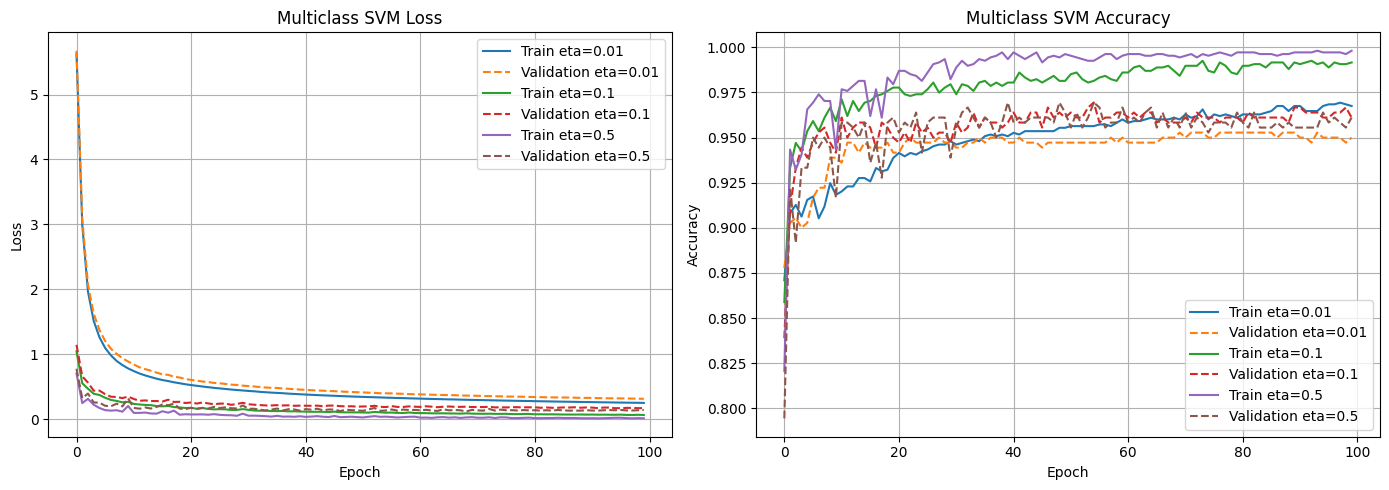


Task 25: Regularization Comparison


,Lambda,Train Loss,Validation Loss,Train Accuracy,Validation Accuracy
0,0.0000,0.0122,0.1406,0.9981,0.9611
1,0.0001,0.0252,0.1500,0.9972,0.9639
2,0.0010,0.1014,0.2185,0.9963,0.9694
3,0.0100,0.4688,0.5601,0.9591,0.9444


Selected SVM lambda: 0.001

Final Multiclass SVM
--------------------
Selected eta: 0.5
Selected lambda: 0.001
Validation Accuracy: 0.9694
Test Accuracy: 0.95
Test Accuracy (%): 95.0

Softmax vs Multiclass SVM


,Model,Validation Accuracy,Test Accuracy
0,Softmax,0.9667,0.9528
1,Multiclass SVM,0.9694,0.9500



Toy Analysis


,Case,Scores,SVM Loss,Softmax Loss
0,a,"[10, -5, -5]",0.0,0.000001
1,b,"[100, -50, -50]",0.0,0.000000
2,c,"[3.2, 5.1, -1.7]",2.9,2.040355


In [ ]:

# Task 25 — Multiclass hinge vs Softmax

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. Dataset and settings
# --------------------------------------------------

Xtr = X_train_tilde
Xv = X_val_tilde
Xte = X_test_tilde

ytr = y_train
yv = y_val
yte = y_test

N = len(Xtr)
D = Xtr.shape[1]
K = len(np.unique(ytr))

delta = 1.0

print("Training shape:", Xtr.shape)
print("Validation shape:", Xv.shape)
print("Test shape:", Xte.shape)
print("Number of classes:", K)


# --------------------------------------------------
# 2. Weston-Watkins Multiclass SVM Loss and Gradient
# --------------------------------------------------

def multiclass_svm_loss_gradient(X, y, W, lam, delta=1.0):

    N = X.shape[0]

    # Scores: (N, K)
    scores = X @ W

    # Correct class scores
    correct_scores = scores[np.arange(N), y]

    # Margins: score_j - score_true + delta
    margins = scores - correct_scores[:, None] + delta

    # Correct class must not contribute to the loss
    margins[np.arange(N), y] = 0

    # Positive margins only
    positive_margins = np.maximum(0, margins)

    # Average Weston-Watkins loss
    loss = np.sum(positive_margins) / N

    # L2 regularization (exclude bias row)
    loss += (lam / 2) * np.sum(W[1:, :] ** 2)

    # Construct B matrix
    B = (margins > 0).astype(float)

    # Correct class entry = negative sum of other entries
    B[np.arange(N), y] = -np.sum(B, axis=1)

    # Gradient
    grad = (X.T @ B) / N

    # Regularize weights only, not bias
    grad[1:, :] += lam * W[1:, :]

    return loss, grad


# --------------------------------------------------
# 3. Check Loss at W = 0
# --------------------------------------------------

W_zero = np.zeros((D, K))

loss_zero, _ = multiclass_svm_loss_gradient(
    Xtr, ytr, W_zero, lam=0
)

expected_loss = delta * (K - 1)

print("\nLoss at W = 0:", loss_zero)
print("Expected loss:", expected_loss)

assert np.isclose(loss_zero, expected_loss, atol=1e-12)

print("W = 0 loss check: PASSED")


# --------------------------------------------------
# 4. Gradient Check (100 random entries)
# --------------------------------------------------

rng = np.random.default_rng(42)

W_check = rng.normal(0, 0.01, size=(D, K))
lam_check = 0.1
epsilon = 1e-6

_, analytical_grad = multiclass_svm_loss_gradient(
    Xtr[:100], ytr[:100], W_check, lam_check
)

# Select 100 random entries
entries = [
    (rng.integers(D), rng.integers(K))
    for _ in range(100)
]

numerical_grads = []
analytical_grads = []

for i, j in entries:

    W_plus = W_check.copy()
    W_minus = W_check.copy()

    W_plus[i, j] += epsilon
    W_minus[i, j] -= epsilon

    loss_plus, _ = multiclass_svm_loss_gradient(
        Xtr[:100], ytr[:100], W_plus, lam_check
    )

    loss_minus, _ = multiclass_svm_loss_gradient(
        Xtr[:100], ytr[:100], W_minus, lam_check
    )

    numerical = (loss_plus - loss_minus) / (2 * epsilon)
    analytical = analytical_grad[i, j]

    numerical_grads.append(numerical)
    analytical_grads.append(analytical)

numerical_grads = np.array(numerical_grads)
analytical_grads = np.array(analytical_grads)

relative_error = (
    np.linalg.norm(numerical_grads - analytical_grads)
    /
    max(
        1e-12,
        np.linalg.norm(numerical_grads)
        + np.linalg.norm(analytical_grads)
    )
)

print("\nGradient Check")
print("Relative error:", relative_error)

assert relative_error < 1e-5

print("Gradient check: PASSED")


# --------------------------------------------------
# 5. Prediction and Evaluation
# --------------------------------------------------

def predict_svm(X, W):
    return np.argmax(X @ W, axis=1)


def evaluate_svm(X, y, W, lam):
    loss, _ = multiclass_svm_loss_gradient(X, y, W, lam)
    acc = np.mean(predict_svm(X, W) == y)
    return loss, acc


# --------------------------------------------------
# 6. Mini-batch Gradient Descent
# --------------------------------------------------

def train_multiclass_svm(
    X_train, y_train, X_val, y_val,
    eta, lam, epochs=100, batch_size=64
):

    rng = np.random.default_rng(42)

    W = np.zeros((X_train.shape[1], K))

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    N_train = len(X_train)

    for epoch in range(epochs):

        indices = rng.permutation(N_train)

        for start in range(0, N_train, batch_size):

            batch_indices = indices[start:start + batch_size]

            X_batch = X_train[batch_indices]
            y_batch = y_train[batch_indices]

            _, grad = multiclass_svm_loss_gradient(
                X_batch, y_batch, W, lam
            )

            W -= eta * grad

        train_loss, train_acc = evaluate_svm(
            X_train, y_train, W, lam
        )

        val_loss, val_acc = evaluate_svm(
            X_val, y_val, W, lam
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

    return W, history


# --------------------------------------------------
# 7. Select Learning Rate (lambda = 0)
# --------------------------------------------------

learning_rates = [0.01, 0.1, 0.5]

eta_results = {}
eta_rows = []

for eta in learning_rates:

    W, history = train_multiclass_svm(
        Xtr, ytr, Xv, yv,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    eta_results[eta] = (W, history)

    eta_rows.append({
        "Learning Rate": eta,
        "Train Loss": history["train_loss"][-1],
        "Validation Loss": history["val_loss"][-1],
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": history["val_acc"][-1]
    })

eta_table = pd.DataFrame(eta_rows)

print("\nTask 25: Learning Rate Comparison")
display(eta_table.round(4))

eta_star_svm = min(
    learning_rates,
    key=lambda eta: eta_results[eta][1]["val_loss"][-1]
)

print("Selected SVM learning rate:", eta_star_svm)


# --------------------------------------------------
# 8. Plot Learning Rate Results
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for eta in learning_rates:

    history = eta_results[eta][1]

    axes[0].plot(
        history["train_loss"],
        label=f"Train eta={eta}"
    )

    axes[0].plot(
        history["val_loss"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

    axes[1].plot(
        history["train_acc"],
        label=f"Train eta={eta}"
    )

    axes[1].plot(
        history["val_acc"],
        linestyle="--",
        label=f"Validation eta={eta}"
    )

axes[0].set_title("Multiclass SVM Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Multiclass SVM Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 9. Select Regularization (using eta*)
# --------------------------------------------------

lambda_values = [0, 1e-4, 1e-3, 1e-2]

lambda_results = {}
lambda_rows = []

for lam in lambda_values:

    W, history = train_multiclass_svm(
        Xtr, ytr, Xv, yv,
        eta=eta_star_svm,
        lam=lam,
        epochs=100,
        batch_size=64
    )

    lambda_results[lam] = (W, history)

    lambda_rows.append({
        "Lambda": lam,
        "Train Loss": history["train_loss"][-1],
        "Validation Loss": history["val_loss"][-1],
        "Train Accuracy": history["train_acc"][-1],
        "Validation Accuracy": history["val_acc"][-1]
    })

lambda_table = pd.DataFrame(lambda_rows)

print("\nTask 25: Regularization Comparison")
display(lambda_table.round(4))

# Highest validation accuracy; ties go to larger lambda
lambda_star_svm = max(
    lambda_values,
    key=lambda lam: (
        lambda_results[lam][1]["val_acc"][-1],
        lam
    )
)

W_svm = lambda_results[lambda_star_svm][0]

print("Selected SVM lambda:", lambda_star_svm)


# --------------------------------------------------
# 10. Final SVM Test Evaluation
# --------------------------------------------------

svm_test_loss, svm_test_acc = evaluate_svm(
    Xte, yte, W_svm, lambda_star_svm
)

svm_val_acc = lambda_results[lambda_star_svm][1]["val_acc"][-1]

print("\nFinal Multiclass SVM")
print("--------------------")
print("Selected eta:", eta_star_svm)
print("Selected lambda:", lambda_star_svm)
print("Validation Accuracy:", round(svm_val_acc, 4))
print("Test Accuracy:", round(svm_test_acc, 4))
print("Test Accuracy (%):", round(svm_test_acc * 100, 2))


# --------------------------------------------------
# 11. Compare SVM Against Softmax
# --------------------------------------------------

comparison = pd.DataFrame([
    {
        "Model": "Softmax",
        "Validation Accuracy": softmax_results["val_accuracy"],
        "Test Accuracy": softmax_results["test_accuracy"]
    },
    {
        "Model": "Multiclass SVM",
        "Validation Accuracy": svm_val_acc,
        "Test Accuracy": svm_test_acc
    }
])

print("\nSoftmax vs Multiclass SVM")
display(comparison.round(4))


# --------------------------------------------------
# 12. Toy Analysis: SVM vs Softmax
# --------------------------------------------------

toy_scores = [
    np.array([10, -5, -5]),
    np.array([100, -50, -50]),
    np.array([3.2, 5.1, -1.7])
]

true_class = 0

def toy_svm_loss(scores, true_class=0, delta=1):
    correct_score = scores[true_class]

    margins = scores - correct_score + delta
    margins[true_class] = 0

    return np.sum(np.maximum(0, margins))


def toy_softmax_loss(scores, true_class=0):
    shifted = scores - np.max(scores)

    log_sum_exp = (
        np.log(np.sum(np.exp(shifted)))
        + np.max(scores)
    )

    return log_sum_exp - scores[true_class]


toy_rows = []

for index, scores in enumerate(toy_scores):

    svm_loss = toy_svm_loss(scores.copy(), true_class)
    softmax_loss = toy_softmax_loss(scores)

    toy_rows.append({
        "Case": chr(97 + index),
        "Scores": scores.tolist(),
        "SVM Loss": svm_loss,
        "Softmax Loss": softmax_loss
    })

toy_table = pd.DataFrame(toy_rows)

print("\nToy Analysis")
display(toy_table.round(6))


# Save Task 25 results
svm_results = {
    "eta_star": eta_star_svm,
    "lambda_star": lambda_star_svm,
    "W": W_svm,
    "val_accuracy": svm_val_acc,
    "test_accuracy": svm_test_acc
}

Training shape: (341, 30)
Validation shape: (114, 30)
Test shape: (114, 30)

Task 26(a): Kernel Comparison (C = 1)


,Kernel,Train Accuracy,Validation Accuracy,Test Accuracy,Support Vectors
0,Linear,0.9883,0.9649,0.9298,30
1,Polynomial,0.9912,0.9825,0.9737,52
2,RBF,0.9824,0.9825,0.9737,88



Task 26(b): Effect of C (Linear SVC)


,C,Train Accuracy,Validation Accuracy,Support Vectors,Margin Width
0,0.001,0.9326,0.9561,175,6.7619
1,0.010,0.9736,0.9737,83,3.1690
2,0.100,0.9795,0.9649,43,1.5669
3,1.000,0.9883,0.9649,30,0.6727
4,10.000,0.9971,0.9386,23,0.2471
5,100.000,1.0000,0.9474,22,0.1460


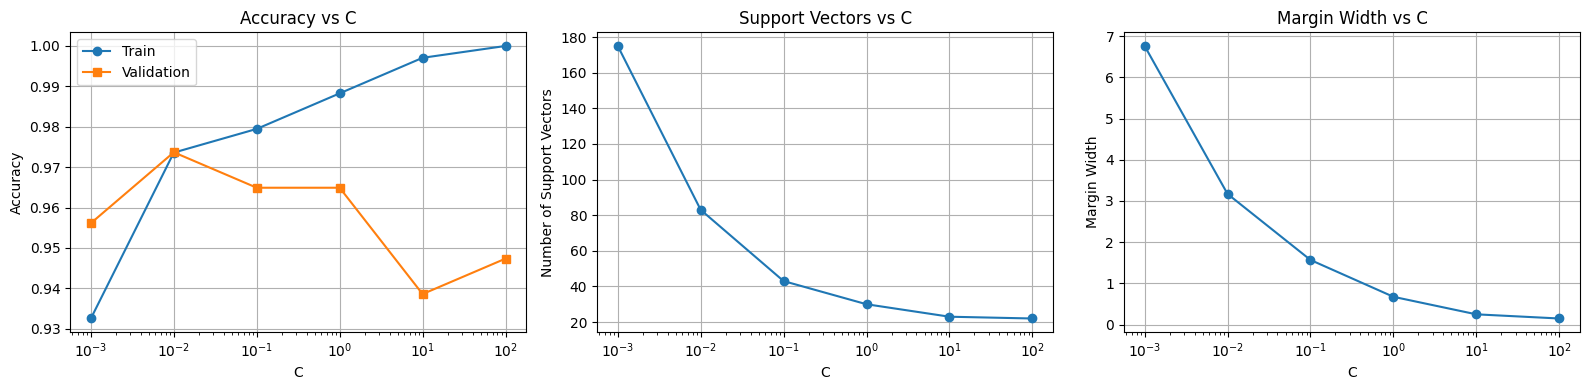


Best C based on validation accuracy:
C = 0.01
Validation Accuracy = 0.9737


In [ ]:
# Task 26 — Kernels and C

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC

# --------------------------------------------------
# 1. Load Breast Cancer dataset
# --------------------------------------------------

data = splits["Breast cancer"]

X_train = data["X_train"]
X_val   = data["X_val"]
X_test  = data["X_test"]

y_train = data["y_train"]
y_val   = data["y_val"]
y_test  = data["y_test"]

# --------------------------------------------------
# 2. Standardize using training statistics only
# --------------------------------------------------

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_val_scaled   = (X_val - mean) / std
X_test_scaled  = (X_test - mean) / std

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)


# --------------------------------------------------
# 3. Compare kernels with C = 1
# --------------------------------------------------

kernel_models = {
    "Linear": SVC(
        kernel="linear",
        C=1
    ),

    "Polynomial": SVC(
        kernel="poly",
        C=1,
        degree=3,
        coef0=1,
        gamma="scale"
    ),

    "RBF": SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    )
}

kernel_rows = []

for name, model in kernel_models.items():

    model.fit(X_train_scaled, y_train)

    train_acc = model.score(X_train_scaled, y_train)
    val_acc = model.score(X_val_scaled, y_val)
    test_acc = model.score(X_test_scaled, y_test)

    support_count = model.n_support_.sum()

    kernel_rows.append({
        "Kernel": name,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Support Vectors": support_count
    })


kernel_table = pd.DataFrame(kernel_rows)

print("\nTask 26(a): Kernel Comparison (C = 1)")
display(kernel_table.round(4))


# --------------------------------------------------
# 4. Sweep C using Linear SVC
# --------------------------------------------------

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

C_rows = []
C_models = {}

for C in C_values:

    model = SVC(
        kernel="linear",
        C=C
    )

    model.fit(X_train_scaled, y_train)

    C_models[C] = model

    train_acc = model.score(X_train_scaled, y_train)
    val_acc = model.score(X_val_scaled, y_val)

    support_count = model.n_support_.sum()

    # For a linear SVC, margin width = 2 / ||w||
    w = model.coef_[0]
    margin_width = 2 / np.linalg.norm(w)

    C_rows.append({
        "C": C,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Support Vectors": support_count,
        "Margin Width": margin_width
    })


C_table = pd.DataFrame(C_rows)

print("\nTask 26(b): Effect of C (Linear SVC)")
display(C_table.round(4))


# --------------------------------------------------
# 5. Plot the effect of C
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    C_table["C"],
    C_table["Train Accuracy"],
    marker="o",
    label="Train"
)

axes[0].plot(
    C_table["C"],
    C_table["Validation Accuracy"],
    marker="s",
    label="Validation"
)

axes[0].set_xscale("log")
axes[0].set_title("Accuracy vs C")
axes[0].set_xlabel("C")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    C_table["C"],
    C_table["Support Vectors"],
    marker="o"
)

axes[1].set_xscale("log")
axes[1].set_title("Support Vectors vs C")
axes[1].set_xlabel("C")
axes[1].set_ylabel("Number of Support Vectors")
axes[1].grid(True)


axes[2].plot(
    C_table["C"],
    C_table["Margin Width"],
    marker="o"
)

axes[2].set_xscale("log")
axes[2].set_title("Margin Width vs C")
axes[2].set_xlabel("C")
axes[2].set_ylabel("Margin Width")
axes[2].grid(True)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Best C based on validation accuracy
# --------------------------------------------------

best_row = C_table.loc[C_table["Validation Accuracy"].idxmax()]

print("\nBest C based on validation accuracy:")
print("C =", best_row["C"])
print("Validation Accuracy =", round(best_row["Validation Accuracy"], 4))


Training shape: (341, 2)
Validation shape: (114, 2)

Gamma Comparison:


,Gamma,Train Accuracy,Validation Accuracy,Support Vectors
0,0.01,0.8827,0.8684,166
1,0.10,0.9003,0.8947,109
2,1.00,0.9120,0.8947,108
3,10.00,0.9296,0.8772,201
4,100.00,0.9824,0.7368,311


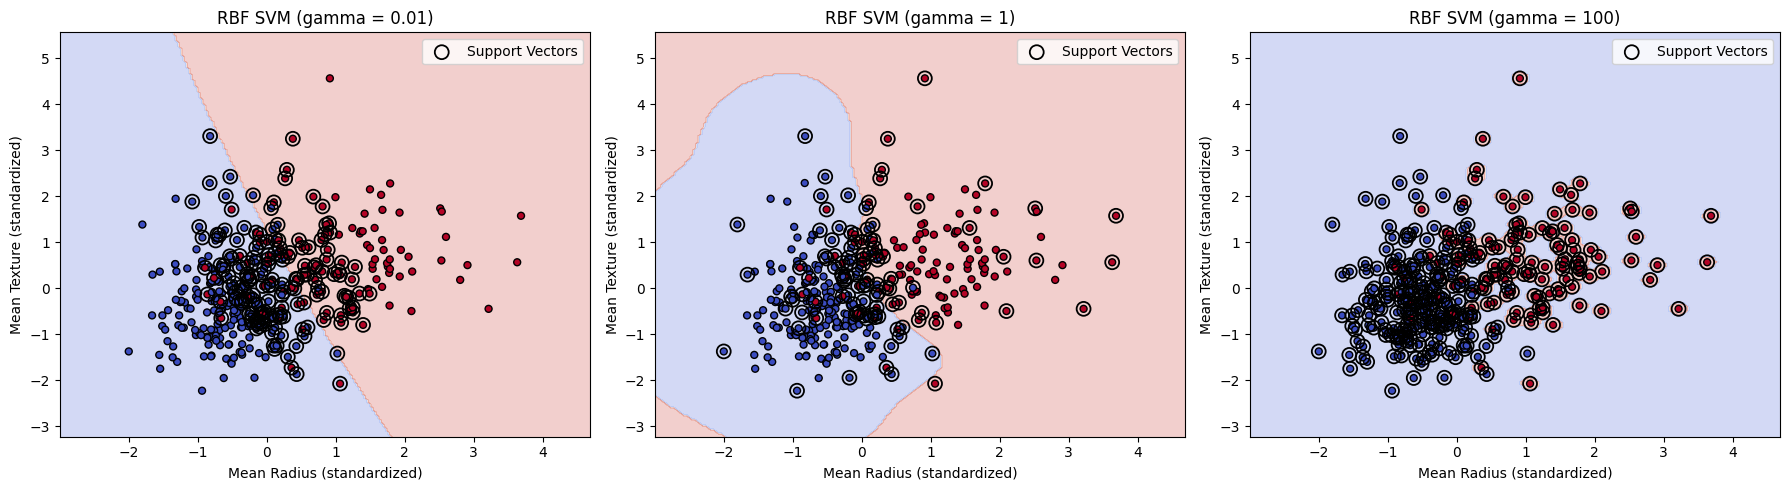

In [ ]:
# Task 27 — Gamma effect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load Breast Cancer data
data = splits["Breast cancer"]

# Find the columns of mean radius and mean texture
feature_names = list(data["feature_names"])
feature_indices = [
    feature_names.index("mean radius"),
    feature_names.index("mean texture")
]

X_train = data["X_train"][:, feature_indices]
X_val = data["X_val"][:, feature_indices]

y_train = data["y_train"]
y_val = data["y_val"]

# 2. Standardize using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

# 3. Train RBF SVM with different gamma values
gamma_values = [0.01, 0.1, 1, 10, 100]

results = []

models = {}

for gamma in gamma_values:

    model = SVC(kernel="rbf", C=1, gamma=gamma)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))
    support_count = model.n_support_.sum()

    results.append({
        "Gamma": gamma,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Support Vectors": support_count
    })

    models[gamma] = model

# Display results
results_df = pd.DataFrame(results)
print("\nGamma Comparison:")
display(results_df.round(4))


# 4. Plot decision regions for three gamma values
plot_gammas = [0.01, 1, 100]

# Create a grid covering the training data
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, gamma in zip(axes, plot_gammas):

    model = models[gamma]

    # Predict the class for every point in the grid
    predictions = model.predict(grid).reshape(xx.shape)

    # Draw decision regions
    ax.contourf(xx, yy, predictions, alpha=0.25, cmap="coolwarm")

    # Draw training points
    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train, cmap="coolwarm",
        edgecolors="black", s=25
    )

    # Circle the support vectors
    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="black",
        linewidths=1.3,
        s=100,
        label="Support Vectors"
    )

    ax.set_title(f"RBF SVM (gamma = {gamma})")
    ax.set_xlabel("Mean Radius (standardized)")
    ax.set_ylabel("Mean Texture (standardized)")
    ax.legend()

plt.tight_layout()
plt.show()


Training shape: (1077, 64)
Test shape: (360, 64)

Best Parameters:
{'C': 100, 'gamma': 1}

Best Cross-Validation Accuracy:
0.9759

Mean Cross-Validation Accuracy:


param_gamma,0.0001,0.0010,0.0100,0.1000,1.0000
param_C,,,,,
0.1,0.1951,0.1951,0.1951,0.1951,0.1951
1.0,0.1951,0.1951,0.1951,0.1951,0.8951
10.0,0.1951,0.1951,0.1951,0.8997,0.9666
100.0,0.1951,0.1951,0.8997,0.9638,0.9759


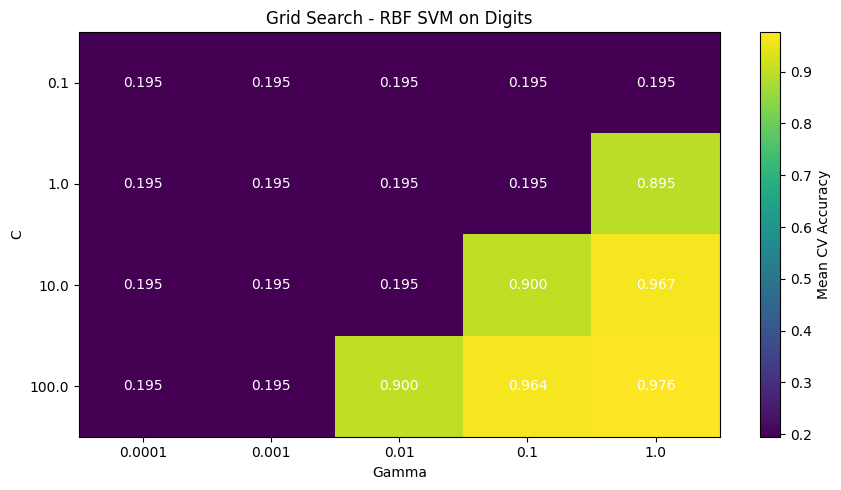


Final Test Accuracy: 0.9778


In [ ]:

# Task 28 — SVM Hyperparameter Tuning on Digits

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

# 1. Load Digits dataset
data = splits["Digits"]

# Divide pixel values by 16
X_train = data["X_train"] / 16.0
X_test = data["X_test"] / 16.0

y_train = data["y_train"]
y_test = data["y_test"]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

# 2. Define parameter values
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1, 1]
}

# 3. Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Run Grid Search
svm = SVC(kernel="rbf")

grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# 5. Display best parameters and CV accuracy
print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

# 6. Create a table of mean CV accuracy
results_df = pd.DataFrame(grid_search.cv_results_)

heatmap_data = results_df.pivot(
    index="param_C",
    columns="param_gamma",
    values="mean_test_score"
)

print("\nMean Cross-Validation Accuracy:")
display(heatmap_data.round(4))

# 7. Plot heatmap
plt.figure(figsize=(9, 5))

plt.imshow(
    heatmap_data.values,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Mean CV Accuracy")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("Grid Search - RBF SVM on Digits")

# Display accuracy values inside the heatmap
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        plt.text(
            j, i,
            f"{heatmap_data.values[i, j]:.3f}",
            ha="center",
            va="center",
            color="white"
        )

plt.tight_layout()
plt.show()

# 8. Evaluate the best model on the test set ONCE
best_model = grid_search.best_estimator_

test_predictions = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print("\nFinal Test Accuracy:", round(test_accuracy, 4))


## Part F — Comparison and Synthesis

In this part, we will connect the concepts learned throughout the assignment and compare the different machine learning models.

We will:
- Compare Linear Regression, Logistic Regression, Softmax, and SVM in terms of their loss functions, gradients, and output meanings.
- Understand the differences between probability predictions and decision margins.
- Discuss when each model is appropriate and how different loss functions handle misclassified samples and outliers.
- Compare the computational costs of linear models and Kernel SVM.
- Summarize the main findings and lessons learned from the experiments.

**The main goal of these two parts** is to understand how SVMs work, how their parameters affect performance, and how they compare with the other machine learning models studied in this assignment.


| Model | Per-sample loss L(s, y) | Gradient ∂L/∂s | Output meaning |
|---|---|---|---|
| Linear Regression | ½(s − y)² | s − y | A continuous numerical prediction |
| Logistic Regression | −[y log(σ(s)) + (1−y) log(1−σ(s))] | σ(s) − y | Probability of the positive class |
| Softmax Classifier | −log(p_y), where p_j = exp(s_j) / Σ exp(s_k) | p − e_y | Probabilities for all classes |
| Binary / Multiclass SVM | Binary: max(0, 1 − ys). Multiclass: Σ(j≠y) max(0, s_j − s_y + 1) | Binary: −y if ys < 1, otherwise 0. Multiclass: B, as defined in Task 25 | Decision scores and margins, not probabilities |



## Conclusions

**(a) When would you choose each model?**

- Ridge Regression is suitable for predicting continuous values, especially when features are correlated. Regularization helps reduce overfitting.
- Logistic Regression is a good choice for binary classification when we need probability estimates.
- Softmax is suitable for multiclass classification when we need probabilities for all classes.
- Linear SVM works well for classification problems where a linear decision boundary is suitable and a clear margin is important.
- Kernel SVM is useful when the data has nonlinear decision boundaries. It can handle more complex patterns using kernels such as RBF and polynomial.

**(b) Probabilities vs. margins**

Logistic Regression and Softmax produce probability estimates. However, these probabilities are not necessarily calibrated. Linear SVM and Kernel SVM produce decision scores or margins, not probabilities. Linear Regression produces numerical predictions rather than class probabilities.

**(c) How do the losses treat badly misclassified outliers?**

Squared loss increases quadratically with the prediction error, so large errors have a strong effect. Logistic loss increases approximately linearly for very confident wrong predictions. Hinge loss also increases linearly when the margin is violated, so its penalty does not grow quadratically.

**(d) Training and prediction costs**

For linear models, one training epoch generally costs O(Nd), while predicting one sample costs O(d). Kernel SVMs can require much more training time and memory because they depend on relationships between training samples. Prediction also becomes more expensive as the number of support vectors increases.

**(e) What surprised me most?**

I was surprised by how strongly the SVM parameters affect the decision boundary. In Task 27, gamma = 100 achieved 98.24% training accuracy but only 73.68% validation accuracy, showing clear overfitting. In Task 28, Grid Search achieved 97.59% cross-validation accuracy and 97.78% test accuracy. I also found that the multiclass SVM and Softmax achieved very similar results on Digits, with 95.00% and 95.28% test accuracy, respectively.





### Bonus 1: Simplified SMO Algorithm for RBF SVM

In this bonus, we will implement a simplified Sequential Minimal Optimization (SMO) algorithm to train an RBF Kernel Support Vector Machine from scratch.

We will:
- Use two features from the Breast Cancer dataset: `mean radius` and `mean texture`.
- Standardize the features using the training data.
- Train an RBF SVM using SMO with C = 1 and gamma = 1.
- Apply the KKT conditions and update pairs of Lagrange multipliers.
- Check the learned multipliers and compare our model with Scikit-learn.

The goal is to understand how SMO trains an SVM and compare our implementation with an existing library.

In [ ]:
# Bonus 1

import numpy as np
from sklearn.svm import SVC

# Get Breast Cancer data
data = splits["Breast cancer"]

# Select two features
feature_names = list(data["feature_names"])
radius_idx = feature_names.index("mean radius")
texture_idx = feature_names.index("mean texture")

X_train = data["X_train"][:, [radius_idx, texture_idx]]
X_test = data["X_test"][:, [radius_idx, texture_idx]]

y_train = np.asarray(data["y_train"]).ravel()
y_test = np.asarray(data["y_test"]).ravel()

# Convert labels from 0/1 to -1/+1
y_train = 2 * y_train - 1
y_test = 2 * y_test - 1

# Standardize features using training data
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std


# RBF Kernel
def rbf_kernel(X1, X2, gamma=1):
    distances = (
        np.sum(X1**2, axis=1).reshape(-1, 1)
        + np.sum(X2**2, axis=1)
        - 2 * X1 @ X2.T
    )

    return np.exp(-gamma * np.maximum(distances, 0))


# Simplified SMO Algorithm
def simplified_smo(X, y, C=1, gamma=1, tol=1e-3,
                   max_passes=20, epsilon=1e-5):

    n = len(X)
    alpha = np.zeros(n)
    b = 0.0

    K = rbf_kernel(X, X, gamma)
    rng = np.random.default_rng(42)

    passes = 0

    while passes < max_passes:
        changed = 0

        for i in range(n):

            Ei = np.sum(alpha * y * K[:, i]) + b - y[i]

            if ((y[i] * Ei < -tol and alpha[i] < C - epsilon)
                or (y[i] * Ei > tol and alpha[i] > epsilon)):

                j = rng.integers(0, n - 1)

                if j >= i:
                    j += 1

                Ej = np.sum(alpha * y * K[:, j]) + b - y[j]

                ai_old = alpha[i]
                aj_old = alpha[j]

                # Calculate L and H
                if y[i] != y[j]:
                    L = max(0, aj_old - ai_old)
                    H = min(C, C + aj_old - ai_old)
                else:
                    L = max(0, ai_old + aj_old - C)
                    H = min(C, ai_old + aj_old)

                if L == H:
                    continue

                eta = 2 * K[i, j] - K[i, i] - K[j, j]

                if eta >= 0:
                    continue

                # Update alpha[j]
                alpha[j] = aj_old - y[j] * (Ei - Ej) / eta
                alpha[j] = np.clip(alpha[j], L, H)

                if abs(alpha[j] - aj_old) < epsilon:
                    alpha[j] = aj_old
                    continue

                # Update alpha[i]
                alpha[i] = (
                    ai_old + y[i] * y[j] * (aj_old - alpha[j])
                )

                # Update bias
                b1 = (
                    b - Ei
                    - y[i] * (alpha[i] - ai_old) * K[i, i]
                    - y[j] * (alpha[j] - aj_old) * K[i, j]
                )

                b2 = (
                    b - Ej
                    - y[i] * (alpha[i] - ai_old) * K[i, j]
                    - y[j] * (alpha[j] - aj_old) * K[j, j]
                )

                if epsilon < alpha[i] < C - epsilon:
                    b = b1
                elif epsilon < alpha[j] < C - epsilon:
                    b = b2
                else:
                    b = (b1 + b2) / 2

                changed += 1

        if changed == 0:
            passes += 1
        else:
            passes = 0

    return alpha, b


# Train our SMO model
C = 1
gamma = 1

alpha, b = simplified_smo(
    X_train, y_train,
    C=C,
    gamma=gamma,
    tol=1e-3,
    max_passes=20
)


# Check SMO constraints
print("SMO Constraint Checks:")

print("Minimum alpha:", alpha.min())
print("Maximum alpha:", alpha.max())

equality_value = np.sum(alpha * y_train)
print("Sum(alpha * y):", equality_value)

print(
    "Alpha bounds satisfied:",
    np.all(alpha >= -1e-6) and np.all(alpha <= C + 1e-6)
)

print(
    "Equality constraint satisfied:",
    abs(equality_value) < 1e-6
)


# Predict using our SMO model
K_test = rbf_kernel(X_test, X_train, gamma)

our_scores = K_test @ (alpha * y_train) + b
our_predictions = np.where(our_scores >= 0, 1, -1)


# Train Scikit-learn SVM
sklearn_svm = SVC(
    C=C,
    kernel="rbf",
    gamma=gamma
)

sklearn_svm.fit(X_train, y_train)

sklearn_predictions = sklearn_svm.predict(X_test)


# Compare both models
agreement = np.mean(
    our_predictions == sklearn_predictions
) * 100

our_sv_count = np.sum(alpha > 1e-5)
sklearn_sv_count = np.sum(sklearn_svm.n_support_)

print("\nSMO vs Scikit-learn:")
print("Test prediction agreement:", round(agreement, 2), "%")
print("Our support vectors:", our_sv_count)
print("Scikit-learn support vectors:", sklearn_sv_count)


SMO Constraint Checks:
Minimum alpha: -5.551115123125783e-17
Maximum alpha: 1.0
Sum(alpha * y): -1.7763568394002505e-15
Alpha bounds satisfied: True
Equality constraint satisfied: True

SMO vs Scikit-learn:
Test prediction agreement: 100.0 %
Our support vectors: 109
Scikit-learn support vectors: 108


### Bonus 2: Logistic Regression with Class Imbalance

In this bonus, we will investigate the effect of class imbalance on Logistic Regression using the Breast Cancer dataset.

We will:
- Create an imbalanced training dataset by keeping all benign samples and randomly selecting only 15% of malignant samples.
- Train Logistic Regression using Gradient Descent with and without class weights.
- Use the original test set to evaluate both models.
- Compare Accuracy, Precision, Recall, and Average Precision.
- Plot Precision-Recall curves to visualize the performance of both models.

The goal is to understand how class weighting affects the model's ability to identify minority-class samples and why accuracy alone may not be sufficient for evaluating imbalanced datasets.


Imbalanced training set:
Benign samples: 127
Malignant samples: 32

Without Class Weights
Accuracy: 0.9386
Malignant Precision: 1.0
Malignant Recall: 0.9028
Average Precision: 0.9983

With Class Weights
Accuracy: 0.9649
Malignant Precision: 0.9857
Malignant Recall: 0.9583
Average Precision: 0.9984


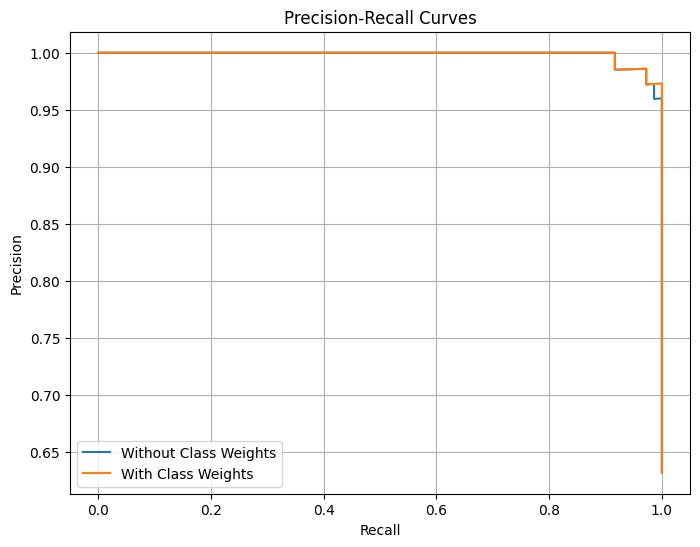

In [ ]:

# Bonus 2

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    precision_recall_curve,
    average_precision_score
)

# Get Breast Cancer data
data = splits["Breast cancer"]

X_train = np.asarray(data["X_train"])
X_test = np.asarray(data["X_test"])

y_train = np.asarray(data["y_train"]).ravel()
y_test = np.asarray(data["y_test"]).ravel()

# Make malignant the positive class
# Original labels: 0 = malignant, 1 = benign
y_train = (y_train == 0).astype(int)
y_test = (y_test == 0).astype(int)

# Create an imbalanced training dataset
rng = np.random.default_rng(0)

benign_indices = np.where(y_train == 0)[0]
malignant_indices = np.where(y_train == 1)[0]

# Keep all benign samples and randomly select 15% of malignant samples
selected_malignant = rng.choice(
    malignant_indices,
    size=max(1, int(0.15 * len(malignant_indices))),
    replace=False
)

selected_indices = np.concatenate([
    benign_indices,
    selected_malignant
])

rng.shuffle(selected_indices)

X_imbalanced = X_train[selected_indices]
y_imbalanced = y_train[selected_indices]

print("Imbalanced training set:")
print("Benign samples:", np.sum(y_imbalanced == 0))
print("Malignant samples:", np.sum(y_imbalanced == 1))


# Standardize using the imbalanced training data
mean = X_imbalanced.mean(axis=0)
std = X_imbalanced.std(axis=0)
std[std == 0] = 1

X_imbalanced = (X_imbalanced - mean) / std
X_test_scaled = (X_test - mean) / std


# Logistic Regression using Gradient Descent
def train_logistic_regression(
    X, y, sample_weights=None,
    lam=0.01, eta=0.1, iterations=3000
):
    n, d = X.shape

    w = np.zeros(d)
    b = 0.0

    if sample_weights is None:
        sample_weights = np.ones(n)

    total_weight = np.sum(sample_weights)

    for epoch in range(iterations):

        scores = np.clip(X @ w + b, -500, 500)
        probabilities = 1 / (1 + np.exp(-scores))

        errors = sample_weights * (probabilities - y)

        dw = (X.T @ errors) / total_weight + lam * w
        db = np.sum(errors) / total_weight

        w -= eta * dw
        b -= eta * db

    return w, b


# Model 1: Without class weights
w_normal, b_normal = train_logistic_regression(
    X_imbalanced,
    y_imbalanced
)


# Model 2: With balanced class weights
class_counts = np.bincount(y_imbalanced)

class_weights = len(y_imbalanced) / (2 * class_counts)

sample_weights = class_weights[y_imbalanced]

w_weighted, b_weighted = train_logistic_regression(
    X_imbalanced,
    y_imbalanced,
    sample_weights=sample_weights
)


# Predict probabilities
def predict_probabilities(X, w, b):
    scores = np.clip(X @ w + b, -500, 500)
    return 1 / (1 + np.exp(-scores))


normal_probs = predict_probabilities(
    X_test_scaled, w_normal, b_normal
)

weighted_probs = predict_probabilities(
    X_test_scaled, w_weighted, b_weighted
)


# Convert probabilities to predictions
normal_predictions = (normal_probs >= 0.5).astype(int)
weighted_predictions = (weighted_probs >= 0.5).astype(int)


# Evaluate both models
def evaluate_model(name, y_true, predictions, probabilities):

    accuracy = accuracy_score(y_true, predictions)

    precision = precision_score(
        y_true, predictions, zero_division=0
    )

    recall = recall_score(
        y_true, predictions, zero_division=0
    )

    avg_precision = average_precision_score(
        y_true, probabilities
    )

    print(f"\n{name}")
    print("Accuracy:", round(accuracy, 4))
    print("Malignant Precision:", round(precision, 4))
    print("Malignant Recall:", round(recall, 4))
    print("Average Precision:", round(avg_precision, 4))


evaluate_model(
    "Without Class Weights",
    y_test, normal_predictions, normal_probs
)

evaluate_model(
    "With Class Weights",
    y_test, weighted_predictions, weighted_probs
)


# Plot Precision-Recall curves
precision_normal, recall_normal, _ = precision_recall_curve(
    y_test, normal_probs
)

precision_weighted, recall_weighted, _ = precision_recall_curve(
    y_test, weighted_probs
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_normal,
    precision_normal,
    label="Without Class Weights"
)

plt.plot(
    recall_weighted,
    precision_weighted,
    label="With Class Weights"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(True)
plt.show()
